# Code 2: Single-qubit tomography and the Bloch sphere

This notebook goes with [Lecture 3](../content/lectures/lecture3.md). A quantum computer only lets us measure in the $Z$ (computational) basis. To reconstruct a qubit's state we need **tomography**: we measure many copies of the state in three different bases to get the Bloch vector

$$
\vec{r} = \big(\langle X\rangle, \langle Y\rangle, \langle Z\rangle\big).
$$

To measure in a different basis we first rotate that basis onto $Z$:

| to measure | apply before measuring | because |
|---|---|---|
| $Z$ | nothing | |
| $X$ | $H$ | $H X H = Z$ |
| $Y$ | $S^\dagger$ then $H$ | $H S^\dagger\, Y\, S H = Z$ |

Then $\langle \sigma \rangle = p(0) - p(1)$ in the rotated basis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.primitives import StatevectorSampler, StatevectorEstimator

sampler = StatevectorSampler(seed=4041)

In [2]:
def plot_bloch_sphere(ax=None):
    """Draw an empty Bloch sphere with labelled x, y, z axes. Returns the 3D axes."""
    if ax is None:
        fig = plt.figure(figsize=(5, 5))
        ax = fig.add_subplot(projection="3d")
    u, v = np.mgrid[0:np.pi:31j, 0:2 * np.pi:30j]
    ax.plot_wireframe(np.sin(u) * np.cos(v), np.sin(u) * np.sin(v), np.cos(u), color="k", alpha=0.08)
    t = np.linspace(0, 2 * np.pi, 100)
    ax.plot(np.cos(t), np.sin(t), 0, color="k", alpha=0.2)            # equator
    for vec, lab in zip(np.eye(3), ["x", "y", "z"]):
        ax.quiver(0, 0, 0, *(1.3 * vec), color="k", arrow_length_ratio=0.08)
        ax.text(*(1.45 * vec), lab, fontsize=13)
    ax.set_box_aspect([1, 1, 1])
    ax.set_axis_off()
    return ax

## Tomography by hand

We prepare an initial state with $R_Y(\theta_0)$ then $R_Z(\varphi_0)$. These are the polar and azimuthal angles on the Bloch sphere. Then we apply the gate we want to study and measure in the chosen basis.

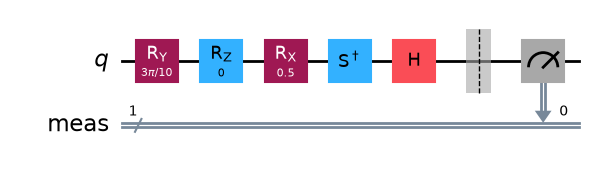

In [3]:
def tomography_circuit(theta0, phi0, gate, angle, basis):
    # Prepare a state, apply a rotation `gate` ('rx', 'ry' or 'rz') by `angle`, then measure in `basis`.
    qc = QuantumCircuit(1)
    qc.ry(theta0, 0)          # initial state: polar angle
    qc.rz(phi0, 0)            #                azimuthal angle
    getattr(qc, gate)(angle, 0)   # the rotation gate we are studying, e.g. qc.rx(angle, 0)
    if basis == "X":
        qc.h(0)
    elif basis == "Y":
        qc.sdg(0)
        qc.h(0)
    qc.measure_all()
    return qc

tomography_circuit(0.3 * np.pi, 0, "rx", 0.5, "Y").draw("mpl")

In [4]:
def measure_bloch_vector(theta0, phi0, gate, angle, shots=4096):
    # Estimate (<X>, <Y>, <Z>) from measurement counts, plus the statistical error on each.
    circuits = [tomography_circuit(theta0, phi0, gate, angle, b) for b in "XYZ"]
    results = sampler.run(circuits, shots=shots).result()
    r, err = [], []
    for res in results:
        counts = res.data.meas.get_counts()
        p0 = counts.get("0", 0) / shots
        r.append(2 * p0 - 1)                       # <sigma> = p0 - p1 = 2 p0 - 1
        err.append(2 * np.sqrt(p0 * (1 - p0) / shots))
    return np.array(r), np.array(err)

theta0, phi0 = 0.3 * np.pi, 0.0
r, err = measure_bloch_vector(theta0, phi0, "rx", 0.0)
exact = [np.sin(theta0) * np.cos(phi0), np.sin(theta0) * np.sin(phi0), np.cos(theta0)]
print("measured  :", np.round(r, 3), "+/-", np.round(err, 3))
print("exact     :", np.round(exact, 3))
print("|r| =", np.linalg.norm(r).round(3), "(a pure state has |r| = 1)")

measured  : [0.801 0.026 0.589] +/- [0.009 0.016 0.013]
exact     : [0.809 0.    0.588]
|r| = 0.995 (a pure state has |r| = 1)


Now sweep the angle of an $R_X$ gate and watch the Bloch vector move:

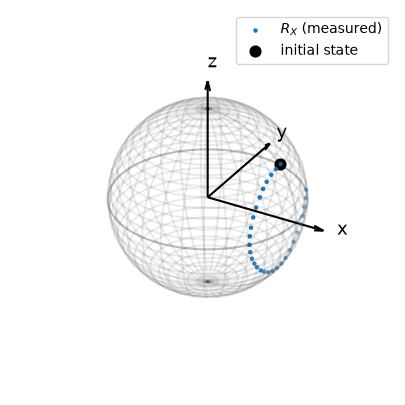

In [5]:
angles = np.linspace(0, 1.5 * np.pi, 30)
path_rx = np.array([measure_bloch_vector(theta0, phi0, "rx", a)[0] for a in angles])

ax = plot_bloch_sphere()
ax.scatter(*path_rx.T, marker=".", c="C0", label="$R_X$ (measured)")
ax.scatter(*path_rx[0], s=60, c="k", label="initial state")
ax.legend()
plt.show()

## The same thing with the Estimator

Measuring an expectation value in several bases is so common that Qiskit has a primitive for it, the **Estimator**. We give it a circuit (without measurements) and the observables $X$, $Y$, $Z$. It handles the basis changes for us.

We also use a circuit **parameter** $\theta$. We build the circuit once, then hand the Estimator a whole array of $\theta$ values in one go.

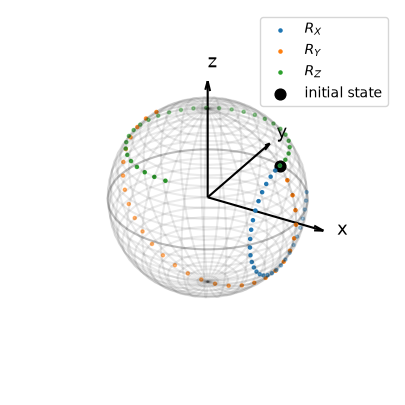

max |Estimator - measured| for R_X: 0.036


In [6]:
theta = Parameter("θ")
observables = [SparsePauliOp(p) for p in "XYZ"]
estimator = StatevectorEstimator()

def rotation_path(gate, theta0=0.3 * np.pi, phi0=0.0, angles=angles):
    qc = QuantumCircuit(1)
    qc.ry(theta0, 0)
    qc.rz(phi0, 0)
    getattr(qc, gate)(theta, 0)
    # observables shape (3, 1) x parameter values shape (N, 1) -> results shape (3, N)
    pub = (qc, [[o] for o in observables], angles[:, None])
    return estimator.run([pub]).result()[0].data.evs

paths = {g: rotation_path(g) for g in ["rx", "ry", "rz"]}

ax = plot_bloch_sphere()
for i, (g, p) in enumerate(paths.items()):
    ax.scatter(*p, marker=".", c=f"C{i}", label=f"$R_{g[1].upper()}$")
ax.scatter(*paths["rx"][:, 0], s=60, c="k", label="initial state")
ax.legend()
plt.show()

print("max |Estimator - measured| for R_X:", np.abs(paths["rx"].T - path_rx).max().round(3))

Each gate rotates the Bloch vector about its own axis. This is what we derived in the section on the Bloch sphere in Lecture 3. The exact Estimator path and our hand-measured path agree to within the shot noise of about $0.02$.

````{admonition} Try this
:class: tip
1. Predict, then check: what path does $R_Z$ trace if the initial state is $|0\rangle$? Why?
2. Reduce `shots` in `measure_bloch_vector` to 100. How does the measured path change? Is $|\vec r|$ still close to 1?
3. Apply $H$ instead of a rotation. Where does it send $|0\rangle$, $|1\rangle$ and $|+\rangle$ on the sphere?
````